# Statistical Exploration of the MS COCO Dataset

## 1. Introduction

This notebook presents a statistical exploration of the training subset of the MS COCO dataset used in the Image Captioning RAG project.

The analysis focuses on understanding the distribution of objects, scene complexity, caption characteristics, and dataset diversity.

## 2. Objectives

The main objectives are:

- Analyse the distribution of object categories.
- Examine scene complexity through the number of objects per image.
- Study caption length, vocabulary size, and part-of-speech distribution.
- Investigate available visual attributes and scene contexts.
- Generate statistical tables and visualisations.

## 3. Scope

This analysis uses exclusively the training split, consisting of 9,900 selected images.

The validation and test splits are excluded from this statistical exploration.

All analyses are based on the available COCO annotations. Information not explicitly provided by the annotations will be identified as requiring additional extraction or inference.

In [32]:
# Standard libraries
import json
from pathlib import Path
from collections import Counter

# Data manipulation
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Locate the project root
PROJECT_ROOT = Path.cwd().resolve()

# Handle execution from the notebooks directory
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent.parent

# Training dataset directories
TRAINING_ROOT = PROJECT_ROOT / "02_processed_data" / "training"

TRAINING_IMAGES = TRAINING_ROOT / "images"
ANNOTATIONS_ROOT = TRAINING_ROOT / "annotations"

# Annotation files
CAPTIONS_FILE = ANNOTATIONS_ROOT / "captions.json"
INSTANCES_FILE = ANNOTATIONS_ROOT / "instances.json"

# Statistical exploration output directories
ANALYSIS_ROOT = (
    PROJECT_ROOT
    / "03_analysis"
    / "01_statistical_exploration"
)

TABLES_DIR = ANALYSIS_ROOT / "outputs" / "tables"
FIGURES_DIR = ANALYSIS_ROOT / "outputs" / "figures"
STATISTICS_DIR = ANALYSIS_ROOT / "outputs" / "statistics"

# Create output directories if necessary
for directory in [TABLES_DIR, FIGURES_DIR, STATISTICS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Training images:", TRAINING_IMAGES)
print("Captions file:", CAPTIONS_FILE)
print("Instances file:", INSTANCES_FILE)

Project root: C:\Users\iso99\Desktop\Ahmed\current\Image-Captioning-RAG
Training images: C:\Users\iso99\Desktop\Ahmed\current\Image-Captioning-RAG\02_processed_data\training\images
Captions file: C:\Users\iso99\Desktop\Ahmed\current\Image-Captioning-RAG\02_processed_data\training\annotations\captions.json
Instances file: C:\Users\iso99\Desktop\Ahmed\current\Image-Captioning-RAG\02_processed_data\training\annotations\instances.json


In [3]:
# Verify required paths
required_paths = [
    TRAINING_IMAGES,
    CAPTIONS_FILE,
    INSTANCES_FILE
]

for path in required_paths:
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{status}: {path}")

assert all(path.exists() for path in required_paths), (
    "One or more required training dataset paths are missing."
)

FOUND: C:\Users\iso99\Desktop\Ahmed\current\Image-Captioning-RAG\02_processed_data\training\images
FOUND: C:\Users\iso99\Desktop\Ahmed\current\Image-Captioning-RAG\02_processed_data\training\annotations\captions.json
FOUND: C:\Users\iso99\Desktop\Ahmed\current\Image-Captioning-RAG\02_processed_data\training\annotations\instances.json


In [4]:
# Load training annotations
with open(CAPTIONS_FILE, "r", encoding="utf-8") as file:
    captions_data = json.load(file)

with open(INSTANCES_FILE, "r", encoding="utf-8") as file:
    instances_data = json.load(file)

print("Training annotations loaded successfully.")

Training annotations loaded successfully.


In [5]:
# Count images and annotations
number_of_images = len(captions_data["images"])
number_of_captions = len(captions_data["annotations"])
number_of_object_annotations = len(instances_data["annotations"])
number_of_categories = len(instances_data["categories"])

# Create a summary table
dataset_summary = pd.DataFrame({
    "Metric": [
        "Training images",
        "Caption annotations",
        "Object annotations",
        "Object categories"
    ],
    "Value": [
        number_of_images,
        number_of_captions,
        number_of_object_annotations,
        number_of_categories
    ]
})

display(dataset_summary)

,Metric,Value
0,Training images,9900
1,Caption annotations,49500
2,Object annotations,71326
3,Object categories,80


In [6]:
dataset_summary.to_csv(
    TABLES_DIR / "dataset_summary.csv",
    index=False
)

print("Dataset summary saved successfully.")

Dataset summary saved successfully.


## 6. Object Class Distribution

This section analyses the frequency of object categories in the training dataset.

The COCO instance annotations are used to count the occurrences of each object category. The 50 most frequent categories are then identified and visualised.

In [7]:
# Extract category definitions
categories = instances_data["categories"]

# Create a mapping between category IDs and category names
category_mapping = {
    category["id"]: category["name"]
    for category in categories
}

print("Number of defined categories:", len(category_mapping))
print("\nAvailable categories:")
print(list(category_mapping.values())[:15])

Number of defined categories: 80

Available categories:
['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird']


In [8]:
# Extract object annotations
object_annotations = instances_data["annotations"]

# Count occurrences of each category ID
category_counts = Counter(
    annotation["category_id"]
    for annotation in object_annotations
)

# Check whether all annotation category IDs have definitions
unknown_category_ids = set(category_counts) - set(category_mapping)

print("Total object annotations:", len(object_annotations))
print("Distinct categories observed:", len(category_counts))
print("Unknown category IDs:", unknown_category_ids)

assert not unknown_category_ids, (
    "Some object annotations refer to undefined category IDs."
)

Total object annotations: 71326
Distinct categories observed: 80
Unknown category IDs: set()


In [9]:
# Build the object frequency table
object_frequency = pd.DataFrame([
    {
        "category_id": category_id,
        "category": category_mapping[category_id],
        "frequency": frequency
    }
    for category_id, frequency in category_counts.items()
])

# Calculate percentage of total object instances
total_objects = object_frequency["frequency"].sum()

object_frequency["percentage"] = (
    object_frequency["frequency"] / total_objects
) * 100

# Sort categories by frequency
object_frequency = (
    object_frequency
    .sort_values("frequency", ascending=False)
    .reset_index(drop=True)
)

# Display the 20 most frequent categories
display(object_frequency.head(20).round(2))

,category_id,category,frequency,percentage
0,1,person,21658,30.36
1,3,car,3807,5.34
2,62,chair,3153,4.42
3,84,book,2166,3.04
4,44,bottle,1858,2.60
5,47,cup,1622,2.27
6,67,dining table,1278,1.79
7,10,traffic light,1123,1.57
8,31,handbag,1013,1.42
9,51,bowl,1012,1.42


In [10]:
# Select the 50 most frequent object categories
top_50_objects = object_frequency.head(50).copy()

display(top_50_objects.round(2))

,category_id,category,frequency,percentage
0,1,person,21658,30.36
1,3,car,3807,5.34
2,62,chair,3153,4.42
3,84,book,2166,3.04
4,44,bottle,1858,2.60
5,47,cup,1622,2.27
6,67,dining table,1278,1.79
7,10,traffic light,1123,1.57
8,31,handbag,1013,1.42
9,51,bowl,1012,1.42


In [11]:
# Save the complete object frequency table
object_frequency.to_csv(
    TABLES_DIR / "object_class_frequency.csv",
    index=False
)

# Save the top 50 categories
top_50_objects.to_csv(
    TABLES_DIR / "top_50_object_classes.csv",
    index=False
)

print("Object frequency tables saved successfully.")

Object frequency tables saved successfully.


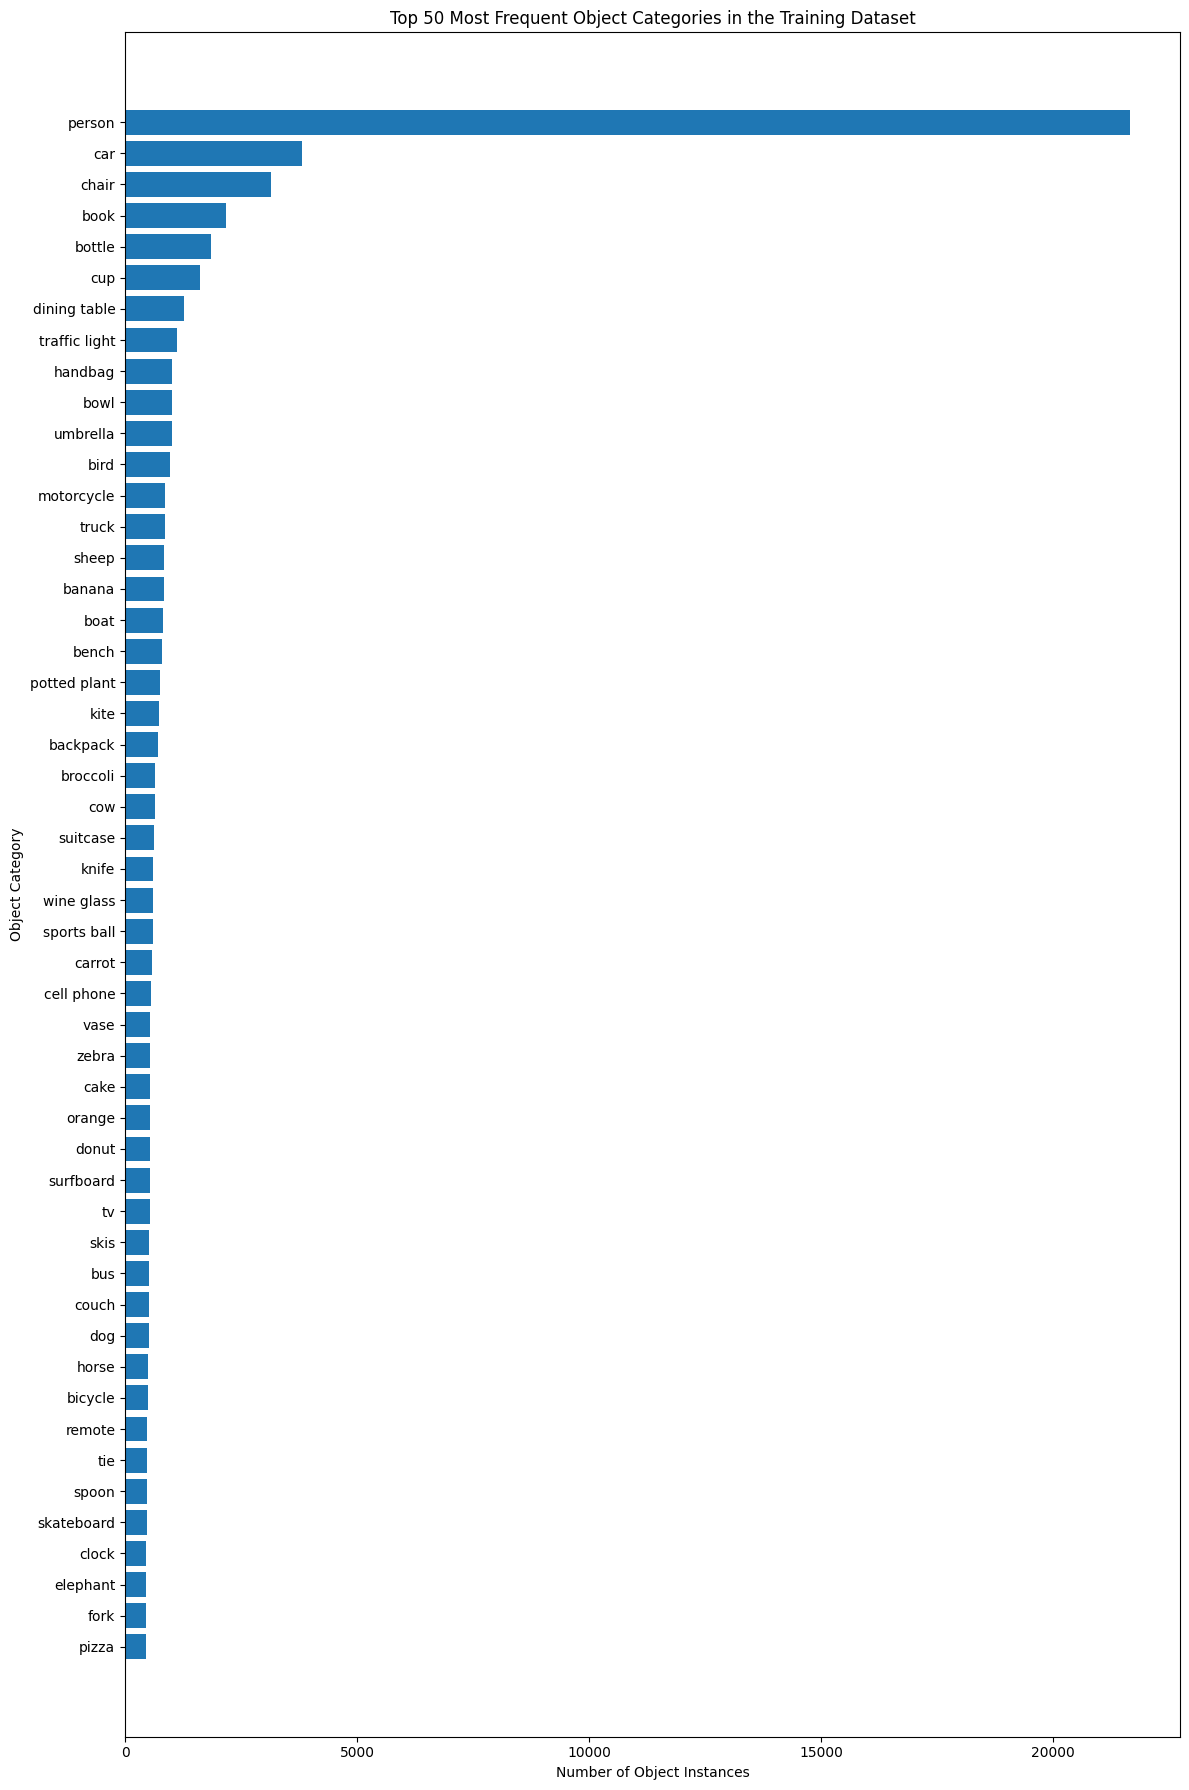

In [12]:
# Prepare data for visualisation
plot_data = top_50_objects.sort_values(
    "frequency",
    ascending=True
)

# Create the figure
plt.figure(figsize=(12, 18))

plt.barh(
    plot_data["category"],
    plot_data["frequency"]
)

plt.xlabel("Number of Object Instances")
plt.ylabel("Object Category")
plt.title("Top 50 Most Frequent Object Categories in the Training Dataset")

plt.tight_layout()

# Save the figure
plt.savefig(
    FIGURES_DIR / "top_50_object_classes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Scene Complexity

This section examines the complexity of scenes in the training dataset by analysing the number of annotated object instances in each image.

The analysis includes:
- Number of objects per image.
- Average, median, minimum, and maximum number of objects.
- Distribution of object counts across images.
- Identification of images with particularly low or high object counts.

Spatial relationships will also be examined according to the information available in the COCO annotations.

In [13]:
# Get all image IDs from the training split
training_image_ids = [
    image["id"]
    for image in captions_data["images"]
]

# Count object annotations for each image
objects_per_image = Counter(
    annotation["image_id"]
    for annotation in object_annotations
)

# Include every training image, even if it has zero annotated objects
scene_complexity = pd.DataFrame({
    "image_id": training_image_ids
})

scene_complexity["object_count"] = (
    scene_complexity["image_id"]
    .map(objects_per_image)
    .fillna(0)
    .astype(int)
)

# Display the first 10 records
display(scene_complexity.head(10))

,image_id,object_count
0,184613,24
1,483108,4
2,328757,7
3,337264,14
4,559665,16
5,579664,8
6,78371,1
7,179558,2
8,450500,28
9,431573,1


In [14]:
# Calculate descriptive statistics
scene_statistics = scene_complexity["object_count"].describe()

print("Scene Complexity Statistics")
print("=" * 40)
print(f"Number of images: {len(scene_complexity)}")
print(f"Total annotated objects: {scene_complexity['object_count'].sum()}")
print(f"Average objects per image: {scene_complexity['object_count'].mean():.2f}")
print(f"Median objects per image: {scene_complexity['object_count'].median():.2f}")
print(f"Standard deviation: {scene_complexity['object_count'].std():.2f}")
print(f"Minimum objects: {scene_complexity['object_count'].min()}")
print(f"Maximum objects: {scene_complexity['object_count'].max()}")

Scene Complexity Statistics
Number of images: 9900
Total annotated objects: 71326
Average objects per image: 7.20
Median objects per image: 4.00
Standard deviation: 7.27
Minimum objects: 0
Maximum objects: 65


In [15]:
# Count images for each object count
object_count_distribution = (
    scene_complexity["object_count"]
    .value_counts()
    .sort_index()
    .reset_index()
)

object_count_distribution.columns = [
    "object_count",
    "number_of_images"
]

# Calculate percentage of images
object_count_distribution["percentage"] = (
    object_count_distribution["number_of_images"]
    / len(scene_complexity)
) * 100

display(object_count_distribution.head(20).round(2))

,object_count,number_of_images,percentage
0,0,86,0.87
1,1,1100,11.11
2,2,1854,18.73
3,3,1192,12.04
4,4,823,8.31
5,5,644,6.51
6,6,500,5.05
7,7,441,4.45
8,8,380,3.84
9,9,308,3.11


In [16]:
object_count_distribution.to_csv(
    TABLES_DIR / "objects_per_image_distribution.csv",
    index=False
)

scene_complexity.to_csv(
    TABLES_DIR / "scene_complexity_per_image.csv",
    index=False
)

print("Scene complexity tables saved successfully.")

Scene complexity tables saved successfully.


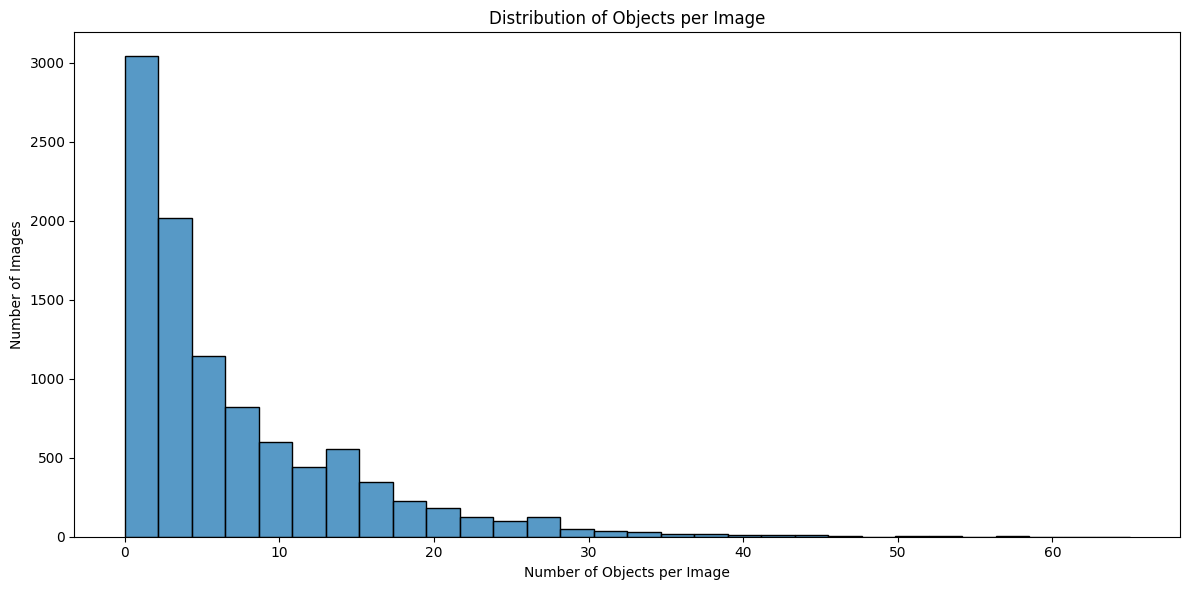

In [17]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=scene_complexity,
    x="object_count",
    bins=30
)

plt.xlabel("Number of Objects per Image")
plt.ylabel("Number of Images")
plt.title("Distribution of Objects per Image")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "objects_per_image_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
# Find the 10 images with the highest object counts
most_complex_images = (
    scene_complexity
    .sort_values("object_count", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

display(most_complex_images)

,image_id,object_count
0,189148,65
1,457718,58
2,108375,57
3,360170,55
4,306267,52
5,143958,52
6,57361,51
7,313434,51
8,378962,51
9,495875,47


In [19]:
most_complex_images.to_csv(
    TABLES_DIR / "most_complex_images.csv",
    index=False
)

print("Most complex images saved successfully.")

Most complex images saved successfully.


In [20]:
# Inspect the fields available in an instance annotation
sample_object = instances_data["annotations"][0]

print("Available object annotation fields:")
print(list(sample_object.keys()))

print("\nExample bounding box:")
print(sample_object.get("bbox"))

print("\nExample object area:")
print(sample_object.get("area"))

Available object annotation fields:
['segmentation', 'area', 'iscrowd', 'image_id', 'bbox', 'category_id', 'id']

Example bounding box:
[77.76, 454.35, 57.15, 75.92]

Example object area:
2610.6542500000005


In [21]:
# Create a structured summary of scene complexity statistics

scene_statistics_summary = {
    "number_of_images": int(len(scene_complexity)),
    "total_annotated_objects": int(scene_complexity["object_count"].sum()),
    "average_objects_per_image": float(scene_complexity["object_count"].mean()),
    "median_objects_per_image": float(scene_complexity["object_count"].median()),
    "standard_deviation": float(scene_complexity["object_count"].std()),
    "minimum_objects_per_image": int(scene_complexity["object_count"].min()),
    "maximum_objects_per_image": int(scene_complexity["object_count"].max())
}

# Convert to a DataFrame
scene_statistics_df = pd.DataFrame(
    list(scene_statistics_summary.items()),
    columns=["Metric", "Value"]
)

# Save as CSV
scene_statistics_df.to_csv(
    STATISTICS_DIR / "scene_complexity_statistics.csv",
    index=False
)

# Save as JSON
with open(
    STATISTICS_DIR / "scene_complexity_statistics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(scene_statistics_summary, file, indent=4)

display(scene_statistics_df)

print("Scene complexity statistics saved successfully.")

,Metric,Value
0,number_of_images,9900.000000
1,total_annotated_objects,71326.000000
2,average_objects_per_image,7.204646
3,median_objects_per_image,4.000000
4,standard_deviation,7.267043
5,minimum_objects_per_image,0.000000
6,maximum_objects_per_image,65.000000


Scene complexity statistics saved successfully.


In [22]:
# Inspect the structure of caption annotations

print("Caption annotation fields:")
print(captions_data["annotations"][0].keys())

print("\nExample caption annotation:")
print(captions_data["annotations"][0])

print("\nTotal number of captions:")
print(len(captions_data["annotations"]))

Caption annotation fields:
dict_keys(['image_id', 'id', 'caption'])

Example caption annotation:
{'image_id': 149, 'id': 481005, 'caption': 'People gathered outside in a big field on a cloudy day'}

Total number of captions:
49500


In [23]:
# Extract caption texts
captions = [
    annotation["caption"]
    for annotation in captions_data["annotations"]
]

# Calculate the number of words in each caption
caption_lengths = [
    len(caption.split())
    for caption in captions
]

# Create a DataFrame
caption_length_df = pd.DataFrame({
    "caption": captions,
    "word_count": caption_lengths
})

# Calculate descriptive statistics
caption_statistics = {
    "total_captions": int(len(captions)),
    "average_words_per_caption": float(np.mean(caption_lengths)),
    "median_words_per_caption": float(np.median(caption_lengths)),
    "standard_deviation": float(np.std(caption_lengths)),
    "minimum_words": int(np.min(caption_lengths)),
    "maximum_words": int(np.max(caption_lengths))
}

caption_statistics_df = pd.DataFrame(
    list(caption_statistics.items()),
    columns=["Metric", "Value"]
)

display(caption_statistics_df)

,Metric,Value
0,total_captions,49500.000000
1,average_words_per_caption,10.462121
2,median_words_per_caption,10.000000
3,standard_deviation,2.391069
4,minimum_words,6.000000
5,maximum_words,44.000000


In [24]:
# Save caption length statistics
caption_statistics_df.to_csv(
    STATISTICS_DIR / "caption_length_statistics.csv",
    index=False
)

with open(
    STATISTICS_DIR / "caption_length_statistics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(caption_statistics, file, indent=4)

# Save individual caption lengths
caption_length_df.to_csv(
    TABLES_DIR / "caption_lengths.csv",
    index=False
)

print("Caption statistics saved successfully.")

Caption statistics saved successfully.


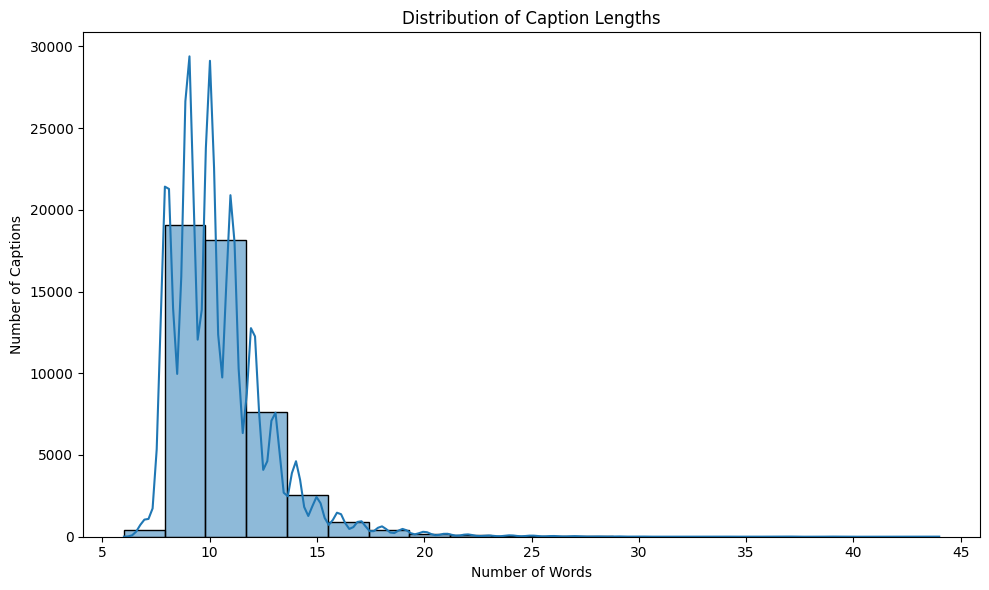

In [25]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=caption_length_df,
    x="word_count",
    bins=20,
    kde=True
)

plt.title("Distribution of Caption Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Captions")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "caption_length_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
import re
from collections import Counter

# Normalise and tokenize captions
all_words = []

for caption in captions:
    caption = caption.lower()
    words = re.findall(r"\b[a-z]+\b", caption)
    all_words.extend(words)

# Count word frequencies
word_frequencies = Counter(all_words)

# Calculate vocabulary statistics
vocabulary_statistics = {
    "total_word_occurrences": len(all_words),
    "vocabulary_size": len(word_frequencies),
    "average_word_frequency": float(np.mean(list(word_frequencies.values()))),
    "most_frequent_word": word_frequencies.most_common(1)[0][0],
    "most_frequent_word_count": word_frequencies.most_common(1)[0][1]
}

vocabulary_statistics_df = pd.DataFrame(
    list(vocabulary_statistics.items()),
    columns=["Metric", "Value"]
)

display(vocabulary_statistics_df)

,Metric,Value
0,total_word_occurrences,518774
1,vocabulary_size,9514
2,average_word_frequency,54.527433
3,most_frequent_word,a
4,most_frequent_word_count,81950


In [27]:
top_words = word_frequencies.most_common(30)

top_words_df = pd.DataFrame(
    top_words,
    columns=["Word", "Frequency"]
)

display(top_words_df)

# Save the results
top_words_df.to_csv(
    TABLES_DIR / "top_30_frequent_words.csv",
    index=False
)

vocabulary_statistics_df.to_csv(
    STATISTICS_DIR / "vocabulary_statistics.csv",
    index=False
)

with open(
    STATISTICS_DIR / "vocabulary_statistics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(vocabulary_statistics, file, indent=4)

,Word,Frequency
0,a,81950
1,on,17954
2,of,17051
3,the,16502
4,in,15218
5,with,12976
6,and,11998
7,is,8400
8,man,6082
9,to,5784


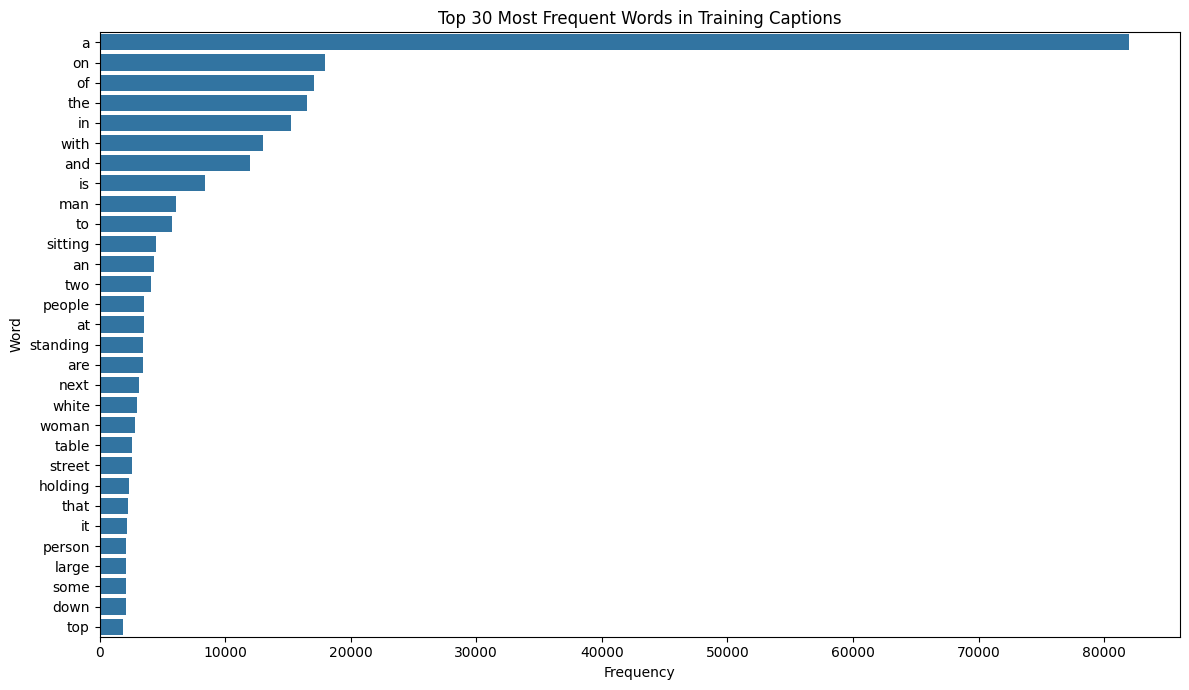

In [28]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_words_df,
    x="Frequency",
    y="Word"
)

plt.title("Top 30 Most Frequent Words in Training Captions")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_30_frequent_words.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
%pip install spacy

In [ ]:
!python -m spacy download en_core_web_sm

In [31]:
%pip install --upgrade typing_extensions

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [34]:
from importlib.metadata import version, PackageNotFoundError

try:
    print("typing_extensions version:", version("typing_extensions"))
except PackageNotFoundError:
    print("typing_extensions is not installed.")

typing_extensions version: 4.16.0


In [35]:
from typing_extensions import Sentinel

print("Sentinel is available!")

Sentinel is available!


In [36]:
import spacy

nlp = spacy.load("en_core_web_sm")

print("spaCy version:", spacy.__version__)
print("English model loaded successfully!")

spaCy version: 3.8.18
English model loaded successfully!


In [37]:
# Process all training captions
pos_counts = Counter()

for caption in captions:
    doc = nlp(caption)

    for token in doc:
        if not token.is_space and not token.is_punct:
            pos_counts[token.pos_] += 1

# Convert counts into a DataFrame
pos_distribution = pd.DataFrame(
    pos_counts.items(),
    columns=["POS", "Frequency"]
)

pos_distribution["Percentage"] = (
    pos_distribution["Frequency"]
    / pos_distribution["Frequency"].sum()
    * 100
)

pos_distribution = pos_distribution.sort_values(
    by="Frequency",
    ascending=False
).reset_index(drop=True)

display(pos_distribution)

,POS,Frequency,Percentage
0,NOUN,179165,34.527382
1,DET,106217,20.469371
2,ADP,87364,16.836158
3,VERB,50435,9.719468
4,ADJ,37191,7.167180
5,AUX,12222,2.355335
6,CCONJ,12178,2.346856
7,PRON,11551,2.226025
8,ADV,7420,1.429929
9,NUM,6325,1.218908


In [38]:
pos_distribution.to_csv(
    TABLES_DIR / "pos_distribution.csv",
    index=False
)

pos_statistics = {
    "total_tagged_tokens": int(pos_distribution["Frequency"].sum()),
    "number_of_pos_categories": int(len(pos_distribution)),
    "pos_distribution": {
        row["POS"]: {
            "frequency": int(row["Frequency"]),
            "percentage": float(row["Percentage"])
        }
        for _, row in pos_distribution.iterrows()
    }
}

with open(
    STATISTICS_DIR / "pos_statistics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(pos_statistics, file, indent=4)

print("POS statistics saved successfully.")

POS statistics saved successfully.


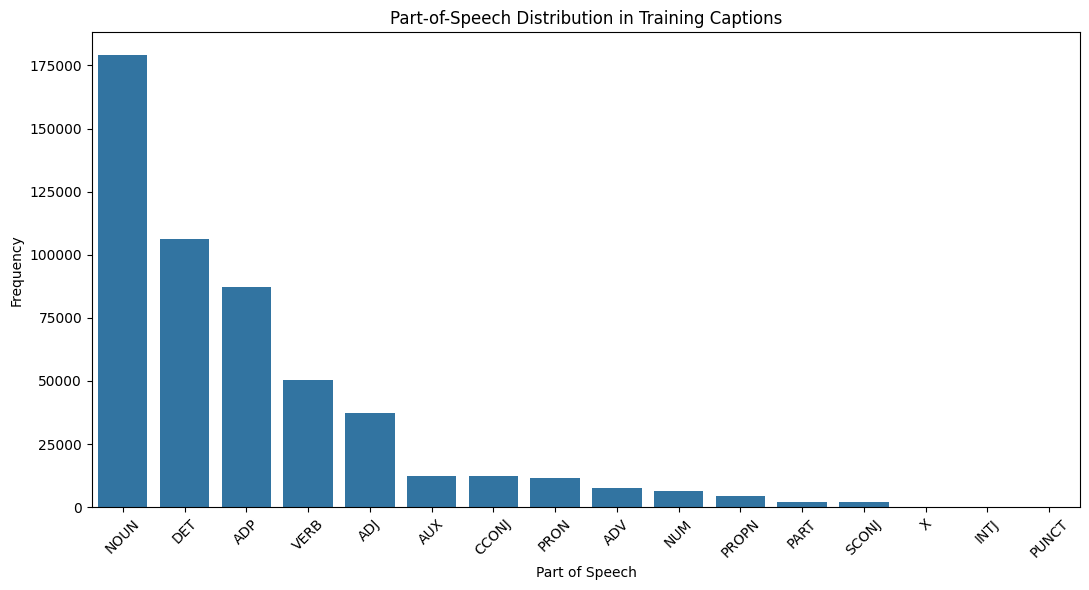

In [39]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=pos_distribution,
    x="POS",
    y="Frequency"
)

plt.title("Part-of-Speech Distribution in Training Captions")
plt.xlabel("Part of Speech")
plt.ylabel("Frequency")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "pos_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [40]:
# Define lexical categories for diversity analysis

colour_words = [
    "red", "blue", "green", "yellow", "black",
    "white", "orange", "pink", "purple", "brown",
    "gray", "grey"
]

shape_words = [
    "round", "square", "rectangular", "circular",
    "oval", "triangular", "curved", "straight"
]

context_words = {
    "indoor": [
        "indoor", "inside", "room", "kitchen",
        "bedroom", "office", "bathroom"
    ],
    "outdoor": [
        "outdoor", "outside", "street", "park",
        "field", "beach", "garden"
    ],
    "day": [
        "day", "daytime", "sunny", "sunlight"
    ],
    "night": [
        "night", "nighttime", "dark", "evening"
    ]
}

print("Colour vocabulary:", colour_words)
print("\nShape vocabulary:", shape_words)
print("\nContext vocabulary:", context_words)

Colour vocabulary: ['red', 'blue', 'green', 'yellow', 'black', 'white', 'orange', 'pink', 'purple', 'brown', 'gray', 'grey']

Shape vocabulary: ['round', 'square', 'rectangular', 'circular', 'oval', 'triangular', 'curved', 'straight']

Context vocabulary: {'indoor': ['indoor', 'inside', 'room', 'kitchen', 'bedroom', 'office', 'bathroom'], 'outdoor': ['outdoor', 'outside', 'street', 'park', 'field', 'beach', 'garden'], 'day': ['day', 'daytime', 'sunny', 'sunlight'], 'night': ['night', 'nighttime', 'dark', 'evening']}


In [41]:
import re

# Normalise captions
normalised_captions = [
    re.findall(r"\b[a-z]+\b", caption.lower())
    for caption in captions
]

print("Total captions:", len(normalised_captions))
print("Example:", normalised_captions[0])

Total captions: 49500
Example: ['people', 'gathered', 'outside', 'in', 'a', 'big', 'field', 'on', 'a', 'cloudy', 'day']


In [42]:
from collections import Counter

# Count all colour word occurrences
colour_frequency = Counter()

# Count captions mentioning each colour
colour_caption_count = Counter()

for words in normalised_captions:
    word_counts = Counter(words)

    for colour in colour_words:
        colour_frequency[colour] += word_counts[colour]

        if word_counts[colour] > 0:
            colour_caption_count[colour] += 1

colour_df = pd.DataFrame({
    "Colour": colour_words,
    "Frequency": [colour_frequency[w] for w in colour_words],
    "Captions_Mentioning": [
        colour_caption_count[w] for w in colour_words
    ]
})

colour_df["Caption_Percentage"] = (
    colour_df["Captions_Mentioning"] / len(captions) * 100
)

colour_df = colour_df.sort_values(
    by="Frequency",
    ascending=False
).reset_index(drop=True)

display(colour_df)

,Colour,Frequency,Captions_Mentioning,Caption_Percentage
0,white,2999,2894,5.846465
1,black,1704,1675,3.383838
2,red,1538,1513,3.056566
3,green,1125,1109,2.240404
4,blue,1109,1084,2.189899
5,yellow,734,726,1.466667
6,brown,713,701,1.416162
7,orange,417,410,0.828283
8,pink,255,250,0.505051
9,gray,158,156,0.315152


In [43]:
shape_frequency = Counter()
shape_caption_count = Counter()

for words in normalised_captions:
    word_counts = Counter(words)

    for shape in shape_words:
        shape_frequency[shape] += word_counts[shape]

        if word_counts[shape] > 0:
            shape_caption_count[shape] += 1

shape_df = pd.DataFrame({
    "Shape": shape_words,
    "Frequency": [shape_frequency[w] for w in shape_words],
    "Captions_Mentioning": [
        shape_caption_count[w] for w in shape_words
    ]
})

shape_df["Caption_Percentage"] = (
    shape_df["Captions_Mentioning"] / len(captions) * 100
)

shape_df = shape_df.sort_values(
    by="Frequency",
    ascending=False
).reset_index(drop=True)

display(shape_df)

,Shape,Frequency,Captions_Mentioning,Caption_Percentage
0,round,72,72,0.145455
1,square,52,52,0.105051
2,circular,17,17,0.034343
3,straight,15,15,0.030303
4,rectangular,11,11,0.022222
5,curved,9,9,0.018182
6,oval,3,3,0.006061
7,triangular,2,2,0.004040


In [44]:
context_frequency = Counter()
context_caption_count = Counter()

for words in normalised_captions:
    word_counts = Counter(words)

    for context, terms in context_words.items():
        for term in terms:
            context_frequency[context] += word_counts[term]

        if any(word_counts[term] > 0 for term in terms):
            context_caption_count[context] += 1

context_df = pd.DataFrame({
    "Context": list(context_words.keys()),
    "Frequency": [
        context_frequency[c] for c in context_words
    ],
    "Captions_Mentioning": [
        context_caption_count[c] for c in context_words
    ]
})

context_df["Caption_Percentage"] = (
    context_df["Captions_Mentioning"] / len(captions) * 100
)

display(context_df)

,Context,Frequency,Captions_Mentioning,Caption_Percentage
0,indoor,4551,4328,8.743434
1,outdoor,6557,6365,12.858586
2,day,516,397,0.802020
3,night,350,343,0.692929


In [45]:
# Save tables
colour_df.to_csv(
    TABLES_DIR / "colour_mentions.csv",
    index=False
)

shape_df.to_csv(
    TABLES_DIR / "shape_mentions.csv",
    index=False
)

context_df.to_csv(
    TABLES_DIR / "context_mentions.csv",
    index=False
)

# Save summary statistics
diversity_statistics = {
    "total_training_captions": len(captions),
    "colour": {
        "total_mentions": int(colour_df["Frequency"].sum()),
        "distinct_terms_mentioned": int(
            (colour_df["Frequency"] > 0).sum()
        )
    },
    "shape": {
        "total_mentions": int(shape_df["Frequency"].sum()),
        "distinct_terms_mentioned": int(
            (shape_df["Frequency"] > 0).sum()
        )
    },
    "context": {
        "total_mentions": int(context_df["Frequency"].sum()),
        "groups_with_mentions": int(
            (context_df["Frequency"] > 0).sum()
        )
    }
}

with open(
    STATISTICS_DIR / "diversity_statistics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(diversity_statistics, file, indent=4)

print("Diversity analysis results saved successfully.")

Diversity analysis results saved successfully.


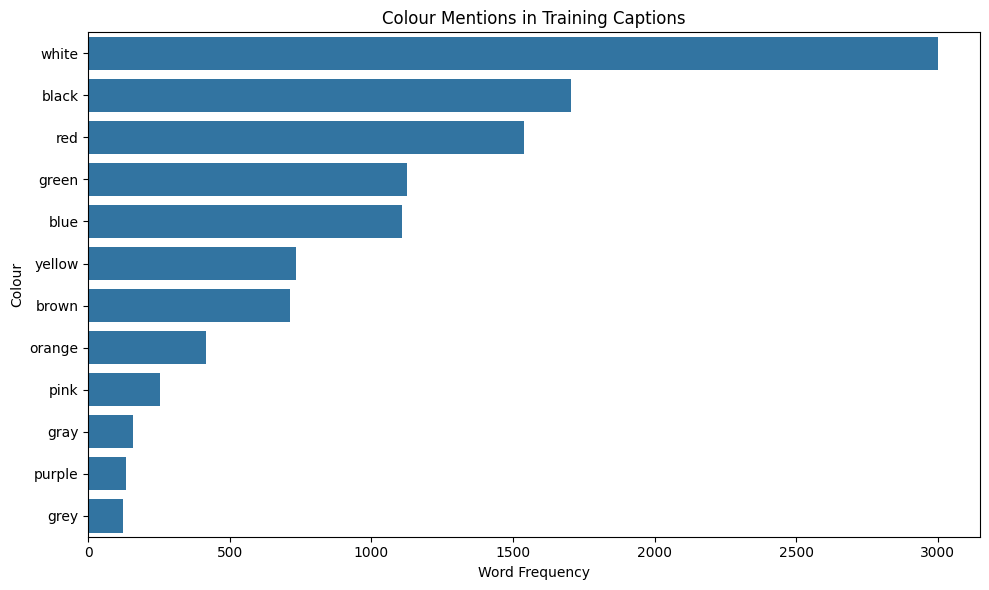

In [46]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=colour_df,
    x="Frequency",
    y="Colour"
)

plt.title("Colour Mentions in Training Captions")
plt.xlabel("Word Frequency")
plt.ylabel("Colour")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "colour_mentions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

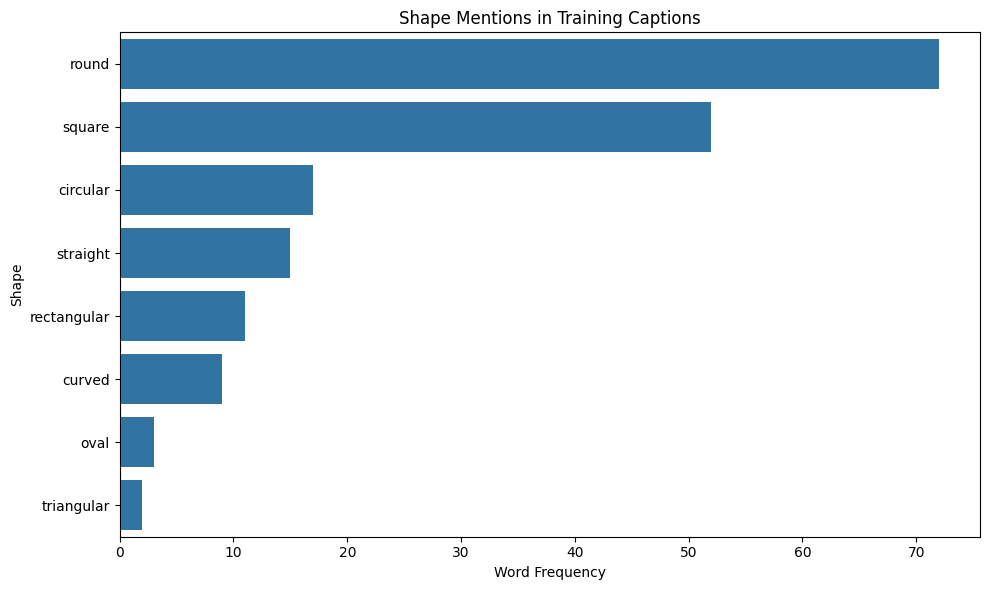

In [47]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=shape_df,
    x="Frequency",
    y="Shape"
)

plt.title("Shape Mentions in Training Captions")
plt.xlabel("Word Frequency")
plt.ylabel("Shape")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "shape_mentions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

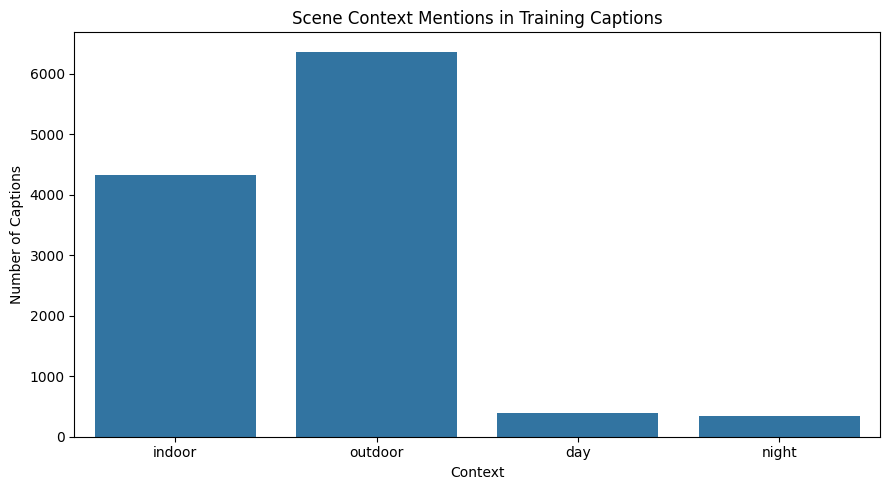

In [48]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=context_df,
    x="Context",
    y="Captions_Mentioning"
)

plt.title("Scene Context Mentions in Training Captions")
plt.xlabel("Context")
plt.ylabel("Number of Captions")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "context_mentions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [49]:
colour_df["Colour"] = colour_df["Colour"].replace({
    "grey": "gray"
})

colour_df = (
    colour_df.groupby("Colour", as_index=False)
    .agg({
        "Frequency": "sum",
        "Captions_Mentioning": "sum"
    })
)

colour_df["Caption_Percentage"] = (
    colour_df["Captions_Mentioning"] / len(captions) * 100
)

colour_df = colour_df.sort_values(
    "Frequency",
    ascending=False
).reset_index(drop=True)

In [51]:
from collections import defaultdict

# Map each image to the set of object categories present
image_objects = defaultdict(set)

for annotation in instances_data["annotations"]:
    image_id = annotation["image_id"]
    category_id = annotation["category_id"]

    image_objects[image_id].add(category_id)

print("Images with object annotations:", len(image_objects))
print("Example image categories:", list(image_objects.items())[:3])

Images with object annotations: 9814
Example image categories: [(278435, {1, 18, 4, 31}), (382406, {1, 18, 3}), (235126, {1, 18})]


In [52]:
from itertools import combinations

# Get all category IDs
category_ids = sorted(category_mapping.keys())

# Initialise an empty co-occurrence matrix
cooccurrence_matrix = pd.DataFrame(
    0,
    index=category_ids,
    columns=category_ids
)

# Count category co-occurrences per image
for categories_in_image in image_objects.values():

    # Generate all unique pairs of categories
    for category_a, category_b in combinations(
        sorted(categories_in_image), 2
    ):
        cooccurrence_matrix.loc[category_a, category_b] += 1
        cooccurrence_matrix.loc[category_b, category_a] += 1

# Replace category IDs with category names
cooccurrence_matrix.index = [
    category_mapping[category_id]
    for category_id in cooccurrence_matrix.index
]

cooccurrence_matrix.columns = [
    category_mapping[category_id]
    for category_id in cooccurrence_matrix.columns
]

print("Co-occurrence matrix shape:", cooccurrence_matrix.shape)

display(cooccurrence_matrix.iloc[:10, :10])

Co-occurrence matrix shape: (80, 80)


,person,bicycle,car,motorcycle,airplane,bus,train,truck,boat,traffic light
person,0,202,719,276,93,237,144,338,156,203
bicycle,202,0,90,36,1,27,13,33,10,37
car,719,90,0,123,39,168,37,313,17,213
motorcycle,276,36,123,0,2,21,1,56,2,33
airplane,93,1,39,2,0,5,0,61,10,1
bus,237,27,168,21,5,0,10,70,2,63
train,144,13,37,1,0,10,0,15,8,39
truck,338,33,313,56,61,70,15,0,5,90
boat,156,10,17,2,10,2,8,5,0,0
traffic light,203,37,213,33,1,63,39,90,0,0


In [53]:
# Extract unique category pairs from the upper triangle
pair_records = []

for i, category_a in enumerate(cooccurrence_matrix.index):

    for category_b in cooccurrence_matrix.columns[i + 1:]:

        frequency = int(
            cooccurrence_matrix.loc[category_a, category_b]
        )

        if frequency > 0:
            pair_records.append({
                "Category_A": category_a,
                "Category_B": category_b,
                "Cooccurrence_Frequency": frequency
            })

cooccurrence_pairs = pd.DataFrame(pair_records)

cooccurrence_pairs = cooccurrence_pairs.sort_values(
    by="Cooccurrence_Frequency",
    ascending=False
).reset_index(drop=True)

top_30_pairs = cooccurrence_pairs.head(30)

display(top_30_pairs)

,Category_A,Category_B,Cooccurrence_Frequency
0,person,car,719
1,person,chair,641
2,person,handbag,516
3,person,dining table,465
4,chair,dining table,441
5,person,backpack,405
6,person,cup,393
7,cup,dining table,386
8,person,bottle,361
9,person,bench,352


In [54]:
# Save the complete matrix
cooccurrence_matrix.to_csv(
    TABLES_DIR / "object_cooccurrence_matrix.csv"
)

# Save all category pairs
cooccurrence_pairs.to_csv(
    TABLES_DIR / "object_cooccurrence_pairs.csv",
    index=False
)

# Save top 30 pairs
top_30_pairs.to_csv(
    TABLES_DIR / "top_30_object_cooccurrence_pairs.csv",
    index=False
)

print("Object co-occurrence tables saved successfully.")

Object co-occurrence tables saved successfully.


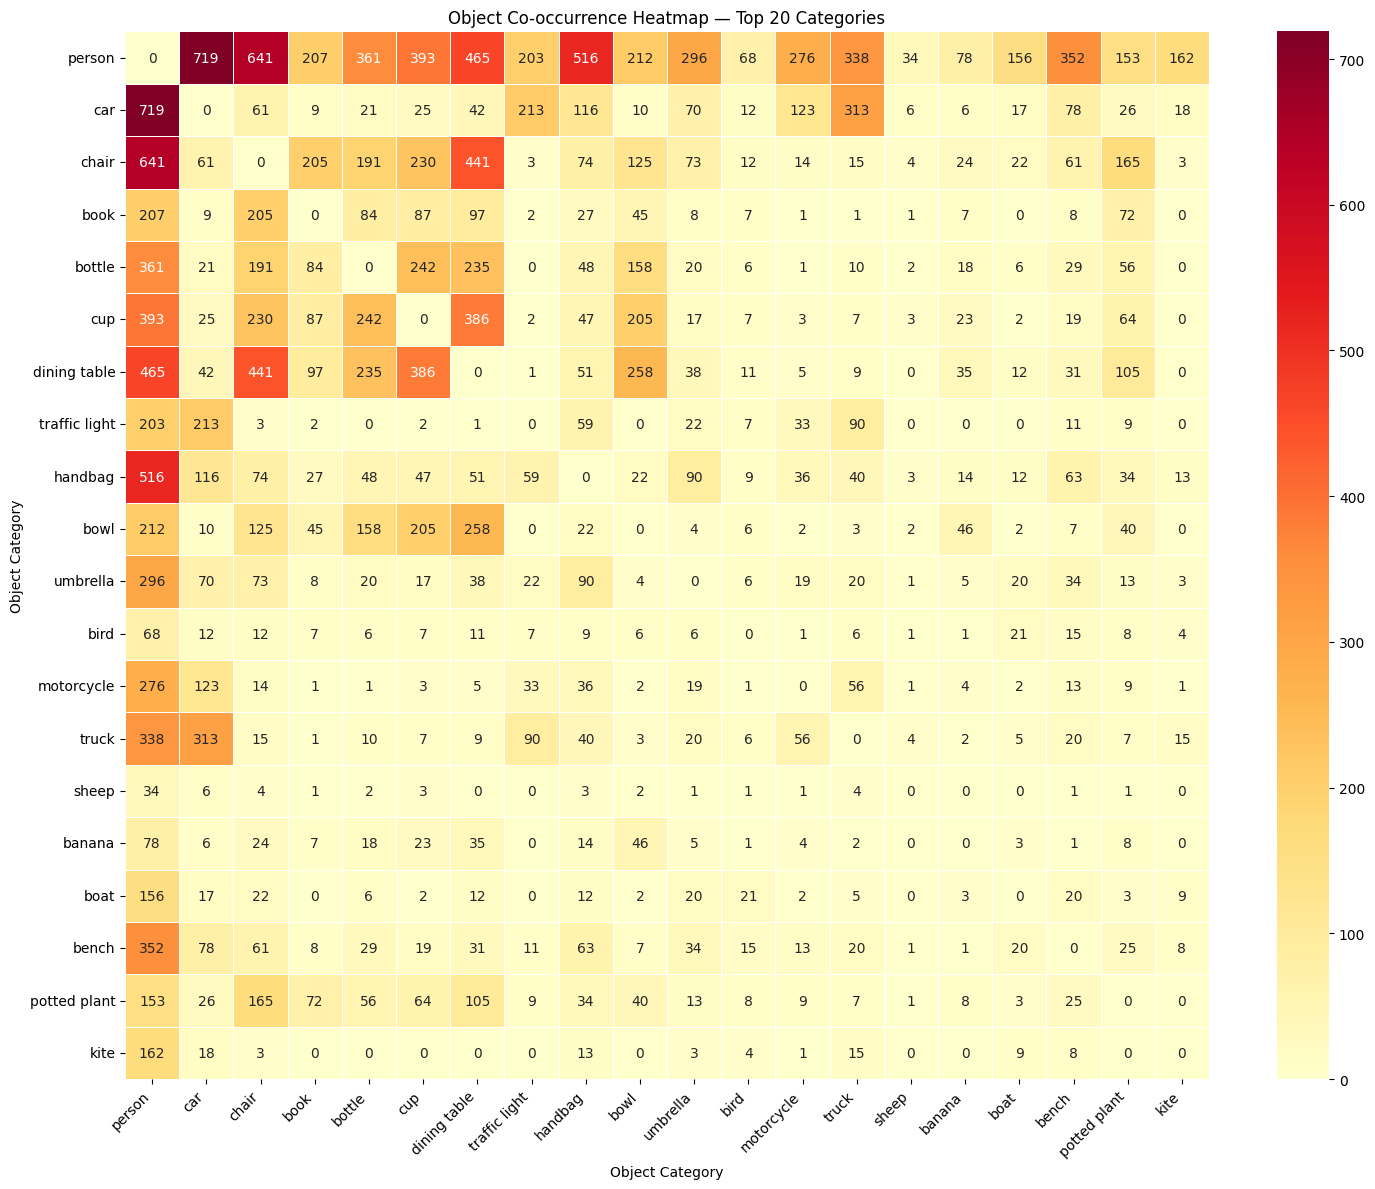

In [55]:
# Select the 20 most frequent categories
top_20_categories = object_frequency.head(20)["category"].tolist()

# Extract the corresponding matrix
top_20_matrix = cooccurrence_matrix.loc[
    top_20_categories,
    top_20_categories
]

plt.figure(figsize=(15, 12))

sns.heatmap(
    top_20_matrix,
    cmap="YlOrRd",
    annot=True,
    fmt="d",
    linewidths=0.5
)

plt.title("Object Co-occurrence Heatmap — Top 20 Categories")
plt.xlabel("Object Category")
plt.ylabel("Object Category")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "object_cooccurrence_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()